## EN4554 Assignment 2

### Jayasundara A.J.M.K.K.B - 220268A

GitHub: [github.com/keshj/dl-for-vision](https://github.com/keshj/dl-for-vision)


In [1]:
import os
import random
from pathlib import Path

import numpy as np
import torch
import torchvision
from torch.utils.data import Dataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

torch 2.7.1+cu126 | torchvision 0.22.1+cu126 | device: cuda


In [2]:
SEED = 42

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id: int) -> None:
    """Pass as `worker_init_fn` to DataLoader so each worker is seeded too."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)

#### Data — download CIFAR-10 and split 45k train / 5k val

Layout under `data/`:

```
data/
├── raw/                    # torchvision download (cifar-10-batches-py)
└── cifar10_split/
    ├── train/data.pt       # 45,000 images
    ├── val/data.pt         #  5,000 images
    └── test/data.pt        # 10,000 images
```

In [3]:
DATA_ROOT = Path("data")
RAW_DIR   = DATA_ROOT / "raw"
SPLIT_DIR = DATA_ROOT / "cifar10_split"
SPLITS    = ("train", "val", "test")
N_VAL     = 5000

CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

def _split_path(name: str) -> Path:
    return SPLIT_DIR / name / "data.pt"

def _to_tensors(ds):
    # ds.data: (N, 32, 32, 3) uint8  ->  (N, 3, 32, 32) uint8
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()
    y = torch.tensor(ds.targets, dtype=torch.long)
    return x, y

def prepare_cifar10(seed: int = SEED, n_val: int = N_VAL) -> None:
    if all(_split_path(s).exists() for s in SPLITS):
        print(f"Found existing splits in {SPLIT_DIR}/ — skipping download and split.")
        return

    print("Splits not found — downloading CIFAR-10 (skipped if raw files are already present)...")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    train_full = torchvision.datasets.CIFAR10(RAW_DIR, train=True,  download=True)
    test_set   = torchvision.datasets.CIFAR10(RAW_DIR, train=False, download=True)

    x_full, y_full = _to_tensors(train_full)
    x_test, y_test = _to_tensors(test_set)

    # Fixed-seed random permutation -> same 45k/5k split every time
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(x_full), generator=g)
    val_idx, train_idx = perm[:n_val], perm[n_val:]

    splits = {
        "train": (x_full[train_idx], y_full[train_idx]),
        "val":   (x_full[val_idx],   y_full[val_idx]),
        "test":  (x_test,            y_test),
    }
    for name, (x, y) in splits.items():
        _split_path(name).parent.mkdir(parents=True, exist_ok=True)
        torch.save({"images": x, "labels": y, "classes": CLASSES}, _split_path(name))
        print(f"  saved {name:5s}: {tuple(x.shape)} -> {_split_path(name)}")

def load_split(name: str):
    d = torch.load(_split_path(name))
    return d["images"], d["labels"]

prepare_cifar10()

x_train, y_train = load_split("train")
x_val,   y_val   = load_split("val")
x_test,  y_test  = load_split("test")

for name, x, y in [("train", x_train, y_train), ("val", x_val, y_val), ("test", x_test, y_test)]:
    counts = torch.bincount(y, minlength=10).tolist()
    print(f"{name:5s}: {tuple(x.shape)}  per-class counts: {counts}")

Found existing splits in data/cifar10_split/ — skipping download and split.
train: (45000, 3, 32, 32)  per-class counts: [4517, 4495, 4502, 4474, 4530, 4516, 4441, 4499, 4494, 4532]
val  : (5000, 3, 32, 32)  per-class counts: [483, 505, 498, 526, 470, 484, 559, 501, 506, 468]
test : (10000, 3, 32, 32)  per-class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## Per-channel normalization with training-set statistics

Mean and std are computed **only on the 45k training split** and then applied to train, val and test.

In [4]:
x = x_train.float().div_(255.0)                 # (N, 3, 32, 32) in [0, 1] with in place division
CIFAR_MEAN = x.mean(dim=(0, 2, 3))              # per-channel over N, H, W
CIFAR_STD  = x.std(dim=(0, 2, 3))
del x

print("train mean (R, G, B):", [round(v, 4) for v in CIFAR_MEAN.tolist()])
print("train std  (R, G, B):", [round(v, 4) for v in CIFAR_STD.tolist()])


class CIFARTensorDataset(Dataset):
    """uint8 images -> float in [0,1] -> optional augmentation -> per-channel normalization."""

    def __init__(self, images, labels, mean=CIFAR_MEAN, std=CIFAR_STD, augment=None):
        self.images, self.labels = images, labels
        self.mean = mean.view(3, 1, 1)
        self.std  = std.view(3, 1, 1)
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i].float().div(255.0)
        if self.augment is not None:
            x = self.augment(x)
        x = (x - self.mean) / self.std
        return x, self.labels[i]


train_ds = CIFARTensorDataset(x_train, y_train, augment=None)
val_ds   = CIFARTensorDataset(x_val,   y_val)
test_ds  = CIFARTensorDataset(x_test,  y_test)

train mean (R, G, B): [0.4916, 0.4825, 0.4469]
train std  (R, G, B): [0.247, 0.2435, 0.2617]


#### Setup:

- **Normalization.** The per-channel mean and standard deviation are computed **only on the 45k training split**, so no information from the validation or test images leaks into training. The same statistics are then applied to all three splits. After normalization, each channel has mean ≈ 0 and standard deviation ≈ 1.


## Task 1: Backpropagation

### (a) Linear, ReLU and softmax cross-entropy with explicit forward/backward


In [5]:
import math

import matplotlib.pyplot as plt
import torch.nn.functional as F

FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


class Linear:
    def __init__(self, in_features, out_features, device="cpu", dtype=torch.float32):
        self.W = torch.randn(in_features, out_features, device=device, dtype=dtype) * math.sqrt(2.0 / in_features)
        self.b = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        log_probs = shifted - shifted.exp().sum(dim=1, keepdim=True).log()
        self.probs = log_probs.exp()
        self.y = y
        return -log_probs[torch.arange(len(y)), y].mean()

    def backward(self):
        d = self.probs.clone()
        d[torch.arange(len(self.y)), self.y] -= 1.0
        return d / len(self.y)


class MLP:
    def __init__(self, sizes, activation=ReLU, device="cpu", dtype=torch.float32):
        self.layers = []
        for i, (fan_in, fan_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(fan_in, fan_out, device, dtype))
            if i < len(sizes) - 2:
                self.layers.append(activation())
        self.criterion = SoftmaxCrossEntropy()

    @property
    def linears(self):
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        d = self.criterion.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def parameters(self):
        return [p for layer in self.linears for p in (layer.W, layer.b)]

    def grads(self):
        return [g for layer in self.linears for g in (layer.dW, layer.db)]

    def sgd_step(self, lr):
        for p, g in zip(self.parameters(), self.grads()):
            p -= lr * g


def flatten_normalize(x):
    x = x.float().div(255.0)
    return ((x - CIFAR_MEAN.view(1, 3, 1, 1)) / CIFAR_STD.view(1, 3, 1, 1)).flatten(1)

#### How the backward pass works

Each layer saves what it needs in `forward`. In `backward` it receives the upstream gradient $\delta = \partial L / \partial(\text{output})$ and returns $\partial L / \partial(\text{input})$, so the layers can be chained with the chain rule. No autograd is used. For a mini-batch $X \in \mathbb{R}^{N \times d}$:

| layer | forward | backward |
|---|---|---|
| Linear | $Z = XW + b$ | $\dfrac{\partial L}{\partial W} = X^\top \delta,\quad \dfrac{\partial L}{\partial b} = \sum_n \delta_n,\quad \dfrac{\partial L}{\partial X} = \delta W^\top$ |
| ReLU | $A = \max(0, Z)$ | $\dfrac{\partial L}{\partial Z} = \delta \odot \mathbf{1}[Z > 0]$ |
| Sigmoid | $A = \sigma(Z)$ | $\dfrac{\partial L}{\partial Z} = \delta \odot A \odot (1 - A)$ |
| Softmax cross-entropy | $L = -\frac{1}{N} \sum_n \log p_{n, y_n}$ | $\dfrac{\partial L}{\partial Z} = \frac{1}{N}(P - Y_{\text{one-hot}})$ |

- The softmax and the cross-entropy are combined into one layer because it is numerically stable.
- The loss is computed from log-probabilities after subtracting the row maximum of the logits (the *log-sum-exp trick*), so `exp` never overflows.


### (b) Gradient check against autograd and centred finite differences

A small MLP (3072-64-32-10) in float64 on 16 training images. The manual gradients are compared with
1. autograd on an identical network built from `torch` ops, over every parameter, and
2. centred finite differences $\frac{L(\theta+\varepsilon) - L(\theta-\varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-6}$, on 50 randomly chosen entries of each parameter tensor.

Relative error: $\dfrac{\lVert g_1 - g_2 \rVert}{\lVert g_1 \rVert + \lVert g_2 \rVert}$.

In [6]:
set_seed(SEED)
gc_model = MLP([3072, 64, 32, 10], dtype=torch.float64)
x_gc = flatten_normalize(x_train[:16]).double()
y_gc = y_train[:16]

gc_model.loss(x_gc, y_gc)
gc_model.backward()
manual_grads = [g.clone() for g in gc_model.grads()]

leaves = [p.clone().requires_grad_() for p in gc_model.parameters()]
h = x_gc
for i in range(0, len(leaves), 2):
    h = h @ leaves[i] + leaves[i + 1]
    if i < len(leaves) - 2:
        h = h.relu()
F.cross_entropy(h, y_gc).backward()
autograd_grads = [p.grad for p in leaves]


def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-20)).item()


EPS = 1e-6
gen = torch.Generator().manual_seed(SEED)
names = [f"{n}{i}" for i in range(1, 4) for n in ("W", "b")]

print(f"{'param':6s} {'shape':>12s} | {'rel err (autograd)':>18s} {'allclose':>8s} | {'rel err (fin. diff)':>19s} {'allclose':>8s}")
for name, p, g_man, g_auto in zip(names, gc_model.parameters(), manual_grads, autograd_grads):
    flat = p.view(-1)
    idx = torch.randperm(flat.numel(), generator=gen)[:50]
    fd = torch.empty(len(idx), dtype=p.dtype)
    for k, j in enumerate(idx):
        orig = flat[j].item()
        flat[j] = orig + EPS
        loss_plus = gc_model.loss(x_gc, y_gc).item()
        flat[j] = orig - EPS
        loss_minus = gc_model.loss(x_gc, y_gc).item()
        flat[j] = orig
        fd[k] = (loss_plus - loss_minus) / (2 * EPS)
    g_sub = g_man.view(-1)[idx]
    print(f"{name:6s} {str(tuple(p.shape)):>12s} | "
          f"{rel_error(g_man, g_auto):18.2e} {str(torch.allclose(g_man, g_auto)):>8s} | "
          f"{rel_error(g_sub, fd):19.2e} {str(torch.allclose(g_sub, fd)):>8s}")

param         shape | rel err (autograd) allclose | rel err (fin. diff) allclose
W1       (3072, 64) |           6.80e-17     True |            2.56e-09     True
b1            (64,) |           7.55e-17     True |            2.17e-09     True
W2         (64, 32) |           4.35e-17     True |            9.39e-10     True
b2            (32,) |           5.56e-17     True |            1.26e-09     True
W3         (32, 10) |           2.76e-17     True |            5.83e-10     True
b3            (10,) |           1.62e-17     True |            5.84e-10     True


#### Interpretation:

- **Against autograd** the relative errors are about $10^{-17}$. Both versions compute the same formulas, so the only difference is rounding error. `torch.allclose` is `True` for every parameter.
- **Against finite differences** the relative errors are about $10^{-9}$. `torch.allclose` is again `True` for every parameter.
- The finite-difference check does not use PyTorch's gradients. Since both checks agree for every layer, the manual backward pass is correct.

### (c) Training with SGD on flattened CIFAR-10

MLP 3072-512-256-10 with ReLU, plain mini-batch SGD (batch 128, learning rate 0.01, 20 epochs), using only the manual forward/backward.

In [7]:
X_tr, Y_tr = flatten_normalize(x_train).to(device), y_train.to(device)
X_va, Y_va = flatten_normalize(x_val).to(device), y_val.to(device)


def evaluate(model, X, Y, batch_size=5000):
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], Y[i:i + batch_size]
        logits = model.forward(xb)
        total_loss += model.criterion.forward(logits, yb).item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


EPOCHS, BATCH_SIZE, LR = 20, 128, 0.01

set_seed(SEED)
mlp = MLP([3072, 512, 256, 10], activation=ReLU, device=device)
shuffle_gen = torch.Generator().manual_seed(SEED)

iter_losses = []
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(len(X_tr), generator=shuffle_gen).to(device)
    for i in range(0, len(X_tr), BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        loss = mlp.loss(X_tr[idx], Y_tr[idx])
        mlp.backward()
        mlp.sgd_step(LR)
        iter_losses.append(loss.item())

    train_loss, train_acc = evaluate(mlp, X_tr, Y_tr)
    val_loss, val_acc = evaluate(mlp, X_va, Y_va)
    for k, v in zip(history, (train_loss, train_acc, val_loss, val_acc)):
        history[k].append(v)
    print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

best_epoch = int(np.argmax(history["val_acc"])) + 1
print(f"\nFinal validation accuracy: {history['val_acc'][-1]:.4f}  (best {max(history['val_acc']):.4f} at epoch {best_epoch})")

epoch  1 | train loss 1.6056 acc 0.4372 | val loss 1.6761 acc 0.4106
epoch  2 | train loss 1.4671 acc 0.4921 | val loss 1.5899 acc 0.4432
epoch  3 | train loss 1.3788 acc 0.5269 | val loss 1.5406 acc 0.4554
epoch  4 | train loss 1.3025 acc 0.5576 | val loss 1.5049 acc 0.4702
epoch  5 | train loss 1.2425 acc 0.5799 | val loss 1.4730 acc 0.4772
epoch  6 | train loss 1.2200 acc 0.5821 | val loss 1.4898 acc 0.4736
epoch  7 | train loss 1.1418 acc 0.6139 | val loss 1.4483 acc 0.4962
epoch  8 | train loss 1.0979 acc 0.6333 | val loss 1.4401 acc 0.4970
epoch  9 | train loss 1.0586 acc 0.6502 | val loss 1.4399 acc 0.4938
epoch 10 | train loss 1.0226 acc 0.6565 | val loss 1.4330 acc 0.5032
epoch 11 | train loss 0.9915 acc 0.6706 | val loss 1.4415 acc 0.5024
epoch 12 | train loss 0.9398 acc 0.6909 | val loss 1.4356 acc 0.5030
epoch 13 | train loss 0.9010 acc 0.7089 | val loss 1.4298 acc 0.5106
epoch 14 | train loss 0.8614 acc 0.7239 | val loss 1.4294 acc 0.5148
epoch 15 | train loss 0.8456 acc 0

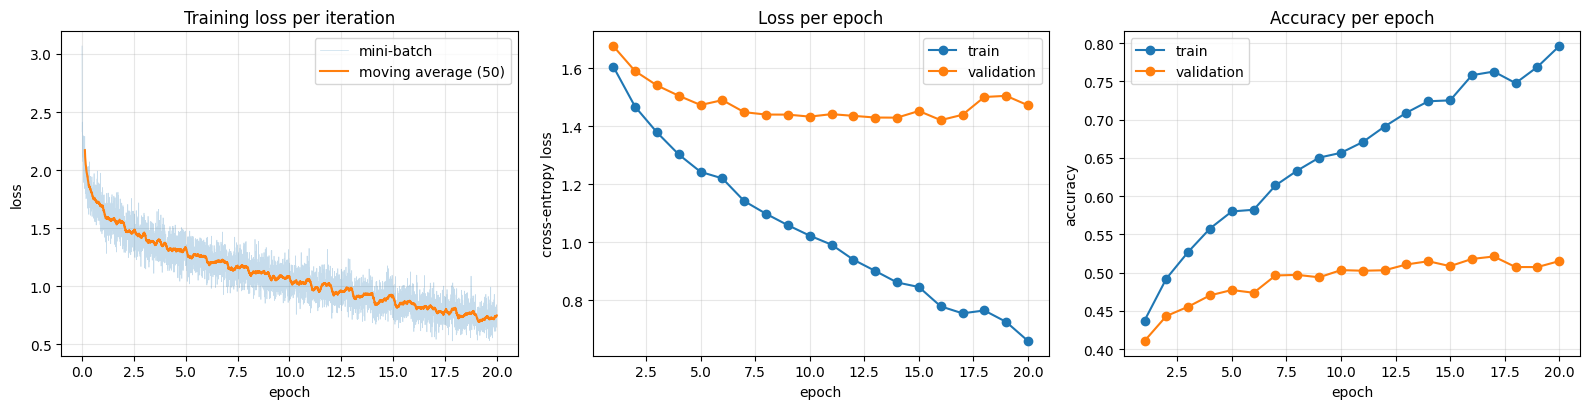

In [8]:
iters_per_epoch = math.ceil(len(X_tr) / BATCH_SIZE)
epochs_axis = np.arange(1, EPOCHS + 1)
smooth = np.convolve(iter_losses, np.ones(50) / 50, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(np.arange(len(iter_losses)) / iters_per_epoch, iter_losses, alpha=0.25, lw=0.5, label="mini-batch")
axes[0].plot((np.arange(len(smooth)) + 49) / iters_per_epoch, smooth, label="moving average (50)")
axes[0].set(xlabel="epoch", ylabel="loss", title="Training loss per iteration")
axes[0].legend()

axes[1].plot(epochs_axis, history["train_loss"], "o-", label="train")
axes[1].plot(epochs_axis, history["val_loss"], "o-", label="validation")
axes[1].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss per epoch")
axes[1].legend()

axes[2].plot(epochs_axis, history["train_acc"], "o-", label="train")
axes[2].plot(epochs_axis, history["val_acc"], "o-", label="validation")
axes[2].set(xlabel="epoch", ylabel="accuracy", title="Accuracy per epoch")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "t1c_training.pdf", bbox_inches="tight")
plt.show()

#### Interpretation

- Most of the loss reduction happens in the first epoch (from $\ln 10 \approx 2.30$ at initialization down to about 1.6). After that the training loss keeps falling steadily.
- **Overfitting.** Validation loss stops improving after about 10 epochs. Training accuracy, however, keeps climbing, so the train–validation gap grows. The network has 1.7M parameters, which is enough to memorize details of the 45k training images, but this does not help on new images.
- **The main limit is the architecture.** Flattening the image throws away its spatial structure. The MLP has no idea that neighbouring pixels are related. Convolutional layers fix this with *local receptive fields* and *weight sharing* across positions.

### (d) Per-layer gradient norm at initialization: sigmoid vs ReLU

Two 10-layer MLPs (3072 → 9 × 256 → 10) with the same He initialization and the same batch of 512 training images, differing only in the hidden activation. One forward/backward pass, then $\lVert \partial L / \partial W_\ell \rVert_F$ for every layer.

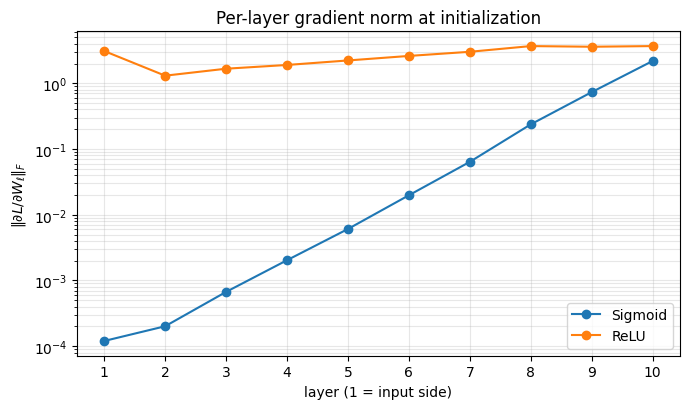

layer    Sigmoid       ReLU
    1   1.20e-04   3.10e+00
    2   2.01e-04   1.31e+00
    3   6.70e-04   1.67e+00
    4   2.03e-03   1.90e+00
    5   6.07e-03   2.23e+00
    6   1.98e-02   2.61e+00
    7   6.38e-02   3.01e+00
    8   2.37e-01   3.68e+00
    9   7.33e-01   3.60e+00
   10   2.18e+00   3.68e+00
Sigmoid: layer 10 / layer 1 gradient-norm ratio = 18165.3
ReLU: layer 10 / layer 1 gradient-norm ratio = 1.2


In [9]:
x_d, y_d = flatten_normalize(x_train[:512]).to(device), y_train[:512].to(device)
deep_sizes = [3072] + [256] * 9 + [10]

grad_norms = {}
for name, act in [("Sigmoid", Sigmoid), ("ReLU", ReLU)]:
    set_seed(SEED)
    deep = MLP(deep_sizes, activation=act, device=device)
    deep.loss(x_d, y_d)
    deep.backward()
    grad_norms[name] = [layer.dW.norm().item() for layer in deep.linears]

layers_axis = np.arange(1, len(deep_sizes))
fig, ax = plt.subplots(figsize=(7, 4.2))
for name, norms in grad_norms.items():
    ax.semilogy(layers_axis, norms, "o-", label=name)
ax.set(xlabel="layer (1 = input side)", ylabel=r"$\|\partial L / \partial W_\ell\|_F$",
       title="Per-layer gradient norm at initialization", xticks=layers_axis)
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "t1d_grad_norms.pdf", bbox_inches="tight")
plt.show()

print(f"{'layer':>5s} {'Sigmoid':>10s} {'ReLU':>10s}")
for l, s, r in zip(layers_axis, grad_norms["Sigmoid"], grad_norms["ReLU"]):
    print(f"{l:5d} {s:10.2e} {r:10.2e}")
for name, norms in grad_norms.items():
    print(f"{name}: layer 10 / layer 1 gradient-norm ratio = {norms[-1] / norms[0]:.1f}")

#### Interpretation

- **Sigmoid: vanishing gradients.** The gradient norm drops by about $3\times$ for every layer moved back from the output. Layer 1 (next to the input) gets a gradient about **18,000× smaller** than layer 10. This is the *vanishing gradient* problem.
- **ReLU: gradients keep their scale.** All ten layers have gradient norms within a factor of about 3 of each other (layer 10 / layer 1 ratio = 1.2).

**Reason:** By the chain rule, going back one layer multiplies the gradient by the transposed weight matrix and then by the derivative of the activation:
$$\delta_\ell = (\delta_{\ell+1} W_{\ell+1}^\top) \odot f'(Z_\ell).$$


## Task 2: Optimizers

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses


In [10]:
import copy

import torch.nn as nn


class ManualSGD(torch.optim.Optimizer):
    """SGD with heavy-ball momentum: v <- mu * v + g, theta <- theta - lr * v (v = g on the first step)."""

    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = g.clone()
                    else:
                        state["momentum_buffer"].mul_(mu).add_(g)
                    g = state["momentum_buffer"]
                p.add_(g, alpha=-lr)
        return loss


class ManualAdam(torch.optim.Optimizer):
    """Adam with bias-corrected first and second moment estimates."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr, (beta1, beta2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)

                state = self.state[p]
                if not state:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p)
                    state["exp_avg_sq"] = torch.zeros_like(p)
                state["step"] += 1
                t, m, v = state["step"], state["exp_avg"], state["exp_avg_sq"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
                m_hat = m / (1 - beta1 ** t)
                v_hat = v / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

#### Matching `torch.optim.SGD` and `torch.optim.Adam`

Two copies of the same small CNN (float64, CPU) are trained for 200 steps on identical mini-batches of 64 training images, one with our optimizer and one with the PyTorch reference.

In [11]:
def tiny_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(16 * 8 * 8, 10),
    ).double()


def normalize_images(x):
    """uint8 (N, 3, 32, 32) -> per-channel normalized float32 images."""
    return (x.float().div(255.0) - CIFAR_MEAN.view(1, 3, 1, 1)) / CIFAR_STD.view(1, 3, 1, 1)


MATCH_STEPS, MATCH_BATCH = 200, 64
x_match = normalize_images(x_train[:MATCH_STEPS * MATCH_BATCH]).double()
y_match = y_train[:MATCH_STEPS * MATCH_BATCH]

match_configs = [
    ("SGD",                  ManualSGD,  torch.optim.SGD,  dict(lr=0.05)),
    ("SGD + momentum",       ManualSGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9)),
    ("SGD + momentum + wd",  ManualSGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=5e-4)),
    ("Adam",                 ManualAdam, torch.optim.Adam, dict(lr=1e-3)),
    ("Adam + wd",            ManualAdam, torch.optim.Adam, dict(lr=1e-3, weight_decay=5e-4)),
]

match_losses = {}
print(f"{'optimizer':22s} | {'max |loss diff|':>15s} {'max |param diff|':>16s} {'allclose':>8s}")
for name, ours_cls, ref_cls, kwargs in match_configs:
    set_seed(SEED)
    model_ours = tiny_cnn()
    model_ref = copy.deepcopy(model_ours)
    opt_ours = ours_cls(model_ours.parameters(), **kwargs)
    opt_ref = ref_cls(model_ref.parameters(), **kwargs)

    losses_ours, losses_ref, max_param_diff = [], [], 0.0
    for i in range(MATCH_STEPS):
        xb = x_match[i * MATCH_BATCH:(i + 1) * MATCH_BATCH]
        yb = y_match[i * MATCH_BATCH:(i + 1) * MATCH_BATCH]
        for model, opt, losses in [(model_ours, opt_ours, losses_ours), (model_ref, opt_ref, losses_ref)]:
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
            losses.append(loss.item())
        max_param_diff = max(max_param_diff, max((a - b).abs().max().item()
                                                 for a, b in zip(model_ours.parameters(), model_ref.parameters())))

    match = all(torch.allclose(a, b) for a, b in zip(model_ours.parameters(), model_ref.parameters()))
    loss_diff = np.abs(np.array(losses_ours) - np.array(losses_ref)).max()
    match_losses[name] = (losses_ours, losses_ref)
    print(f"{name:22s} | {loss_diff:15.2e} {max_param_diff:16.2e} {str(match):>8s}")

optimizer              | max |loss diff| max |param diff| allclose
SGD                    |        0.00e+00         0.00e+00     True
SGD + momentum         |        0.00e+00         0.00e+00     True
SGD + momentum + wd    |        0.00e+00         0.00e+00     True
Adam                   |        6.66e-16         1.67e-16     True
Adam + wd              |        4.44e-16         1.53e-16     True


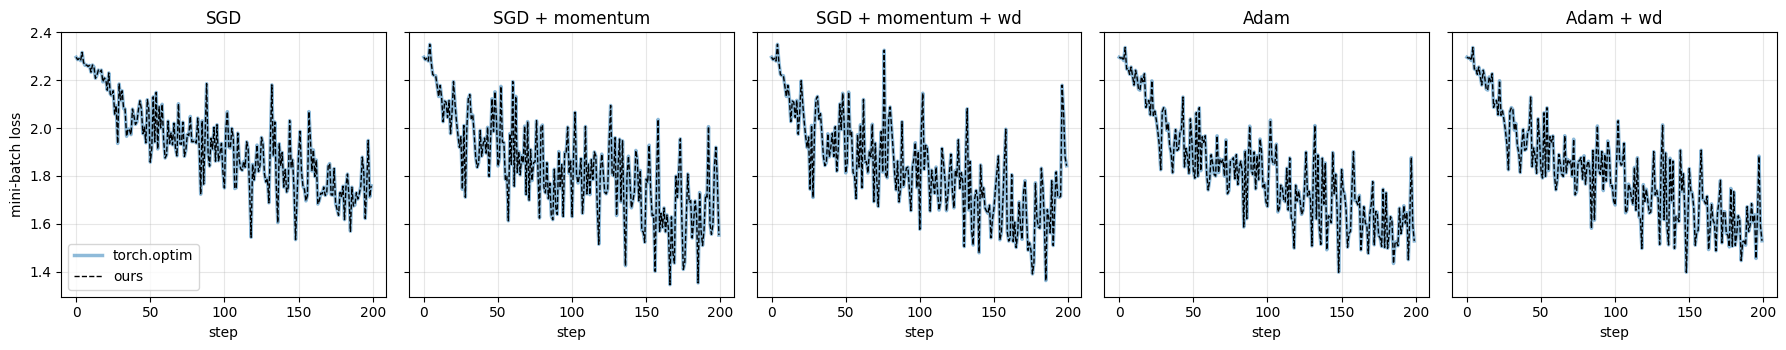

In [12]:
fig, axes = plt.subplots(1, len(match_losses), figsize=(18, 3.6), sharey=True)
for ax, (name, (losses_ours, losses_ref)) in zip(axes, match_losses.items()):
    ax.plot(losses_ref, lw=2.5, alpha=0.5, label="torch.optim")
    ax.plot(losses_ours, "--", lw=1, color="k", label="ours")
    ax.set(xlabel="step", title=name)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mini-batch loss")
axes[0].legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "t2a_optimizer_match.pdf", bbox_inches="tight")
plt.show()

#### Interpretation

- **SGD and SGD with momentum match `torch.optim.SGD` exactly**. Both implementations do the same floating-point operations in the same order, so the results are bit-for-bit identical over all 200 steps.
- **Adam matches `torch.optim.Adam` to about $10^{-16}$**, which is float64 rounding level. 
- **The error does not grow over time.** The largest parameter difference over all 200 steps is still about $10^{-16}$, so there is no drift that would build up during a long training run.
- `torch.allclose` is `True` in every case. This confirms that the momentum buffer (including its first-step initialization $v_1 = g_1$), the bias correction and the coupled L2 weight decay are implemented in the same way as in PyTorch.

### (b) Trajectories on $f(x, y) = \frac{1}{2}(x^2 + 50y^2)$

The Hessian is $\mathrm{diag}(1, 50)$ (condition number 50), so gradient descent is stable only for $\eta < 2/50 = 0.04$.
All three optimizers start at $(-9, 1.5)$ and run for 100 steps:
- SGD with $\eta = 0.035$ (close to the stability limit),
- SGD with momentum, same $\eta = 0.035$ and $\mu = 0.7$,
- Adam with $\eta = 0.3$ and default $\beta_1 = 0.9,\ \beta_2 = 0.999$.

The gradient is exact here, so "SGD" is plain gradient descent.

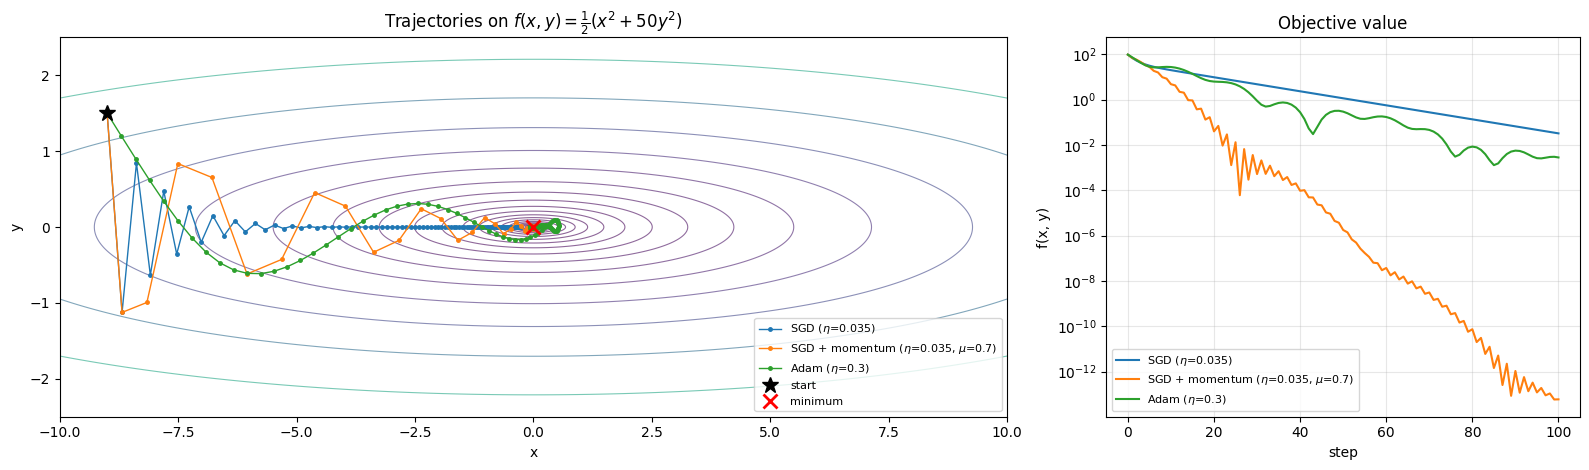

optimizer                                   f after 10  f after 100  steps to f<1e-3
SGD (\eta=0.035)                             2.004e+01    3.258e-02             >100
SGD + momentum (\eta=0.035, \mu=0.7)         4.815e+00    6.003e-14               26
Adam (\eta=0.3)                              2.756e+01    2.819e-03             >100


In [13]:
def quadratic(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


START, N_STEPS = (-9.0, 1.5), 100
traj_configs = {
    r"SGD ($\eta$=0.035)":                    (ManualSGD,  dict(lr=0.035)),
    r"SGD + momentum ($\eta$=0.035, $\mu$=0.7)": (ManualSGD,  dict(lr=0.035, momentum=0.7)),
    r"Adam ($\eta$=0.3)":                     (ManualAdam, dict(lr=0.3)),
}


def optimize_path(opt_cls, kwargs, start=START, n_steps=N_STEPS):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kwargs)
    path, values = [p.detach().clone()], [quadratic(p).item()]
    for _ in range(n_steps):
        opt.zero_grad()
        quadratic(p).backward()
        opt.step()
        path.append(p.detach().clone())
        values.append(quadratic(p).item())
    return torch.stack(path).numpy(), np.array(values)


trajectories = {name: optimize_path(cls, kw) for name, (cls, kw) in traj_configs.items()}

xs, ys = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-2.5, 2.5, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].contour(xs, ys, zs, levels=np.logspace(-2, np.log10(zs.max()), 20), cmap="viridis", alpha=0.6, linewidths=0.8)
for name, (path, _) in trajectories.items():
    axes[0].plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, label=name)
axes[0].plot(*START, "k*", ms=12, label="start")
axes[0].plot(0, 0, "rx", ms=10, mew=2, label="minimum")
axes[0].set(xlabel="x", ylabel="y", title=r"Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$")
axes[0].legend(loc="lower right", fontsize=8)

for name, (_, values) in trajectories.items():
    axes[1].semilogy(values, label=name)
axes[1].set(xlabel="step", ylabel="f(x, y)", title="Objective value")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "t2b_trajectories.pdf", bbox_inches="tight")
plt.show()

print(f"{'optimizer':42s} {'f after 10':>11s} {'f after 100':>12s} {'steps to f<1e-3':>16s}")
for name, (path, values) in trajectories.items():
    below = np.flatnonzero(values < 1e-3)
    steps = str(below[0]) if len(below) else f">{N_STEPS}"
    print(f"{name.replace('$', ''):42s} {values[10]:11.3e} {values[-1]:12.3e} {steps:>16s}")

#### Interpretation

The function is a long, narrow valley: it is 50 times more curved along $y$ than along $x$ (*condition number* $\kappa = 50$).

**SGD (plain gradient descent).** Each coordinate is updated independently: $x \leftarrow (1 - 0.035 \cdot 1)\,x = 0.965\,x$ and $y \leftarrow (1 - 0.035 \cdot 50)\,y = -0.75\,y$.
- Along the steep $y$ direction the factor is negative, so $y$ changes sign every step. This is the *zig-zag* across the valley in the plot.
- Along the flat $x$ direction the factor is 0.965, so $x$ shrinks by only 3.5% per step. After 100 steps it is still at $x \approx -0.26$ and $f \approx 3 \times 10^{-2}$.
- We cannot fix this by increasing $\eta$, because the steep direction only allows $\eta < 2/50 = 0.04$. Above that, $y$ blows up. So **the steep direction limits the learning rate and the flat direction limits the speed**. This is why plain SGD is slow on ill-conditioned problems.

**SGD with momentum ($\mu = 0.7$).**
- Along $x$ the gradient always points the same way, so the velocity builds up and the effective step becomes about $\eta / (1 - \mu) \approx 3.3\times$ larger.
- Along $y$ the gradient flips sign every step, so successive gradients partly cancel in the velocity and the zig-zag is damped.
- As a result, momentum reaches $f < 10^{-3}$ in **26 steps** and $f \approx 6 \times 10^{-14}$ after 100 steps, while SGD never gets below $10^{-3}$. With these settings both directions shrink by the same factor $\sqrt{\mu} \approx 0.84$ per step (the roots of the momentum recursion are complex with modulus $\sqrt{\mu}$), compared with 0.965 per step for SGD along $x$. The path still overshoots the valley floor a few times, because momentum carries the point past the centre before it turns back.

**Adam ($\eta = 0.3$).** Adam divides each coordinate's step by $\sqrt{\hat v}$, a running estimate of the size of that coordinate's gradient.
- This makes the step size roughly $\eta$ in *every* direction, no matter how steep that direction is. In the first steps Adam moves almost the same distance in $x$ and $y$, so the path heads diagonally towards the valley floor instead of zig-zagging. It then follows the valley floor in a smooth, curved path.
- Adam did not need $\eta$ to be tuned to the curvature ($\eta = 0.3$ is almost 10 times the SGD stability limit), which is its main practical advantage.
- Near the minimum, however, Adam slows down and keeps circling around it (from about step 70 on, $f$ only moves up and down between $10^{-3}$ and $10^{-2}$). The step is still about $\eta$ in size, while $\sqrt{\hat v}$ remembers the larger gradients from earlier steps ($\beta_2 = 0.999$ is a long memory). With a constant learning rate, Adam settles into a small region around the minimum instead of converging exactly.

On this simple quadratic, well-tuned momentum is the fastest, because the problem has fixed curvature and momentum is exactly the right fix for a narrow valley. Adam's per-coordinate scaling removes the zig-zag and is much less sensitive to the learning rate, but it does not converge as precisely without learning-rate decay. Plain SGD is the slowest, because its learning rate is limited by the steepest direction.

### (c) Learning-rate sensitivity of a small CNN

A small CNN (three conv–ReLU–max-pool blocks with 32/64/128 channels, then a 256-unit hidden layer; no batch norm) is trained on the 45k training split for 15 epochs with batch size 128, using optimizers from (a). Each optimizer is run at three learning rates, two decades wide, around its usual operating range:

| optimizer | learning rates |
|---|---|
| SGD | $10^{-3}, 10^{-2}, 10^{-1}$ |
| SGD + momentum ($\mu = 0.9$) | $10^{-3}, 10^{-2}, 10^{-1}$ |
| Adam | $10^{-4}, 10^{-3}, 10^{-2}$ |

Every run uses the same initialization and the same mini-batch order (both seeded), so the optimizer and the learning rate are the only things that change.

In [14]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32 x 16 x 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 64 x 8 x 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 x 4 x 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print(f"SmallCNN parameters: {sum(p.numel() for p in SmallCNN().parameters()):,}")

Xi_tr, Yi_tr = normalize_images(x_train).to(device), y_train.to(device)
Xi_va, Yi_va = normalize_images(x_val).to(device), y_val.to(device)


@torch.no_grad()
def evaluate_cnn(model, X, Y, batch_size=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        logits = model(X[i:i + batch_size])
        total_loss += F.cross_entropy(logits, Y[i:i + batch_size], reduction="sum").item()
        correct += (logits.argmax(dim=1) == Y[i:i + batch_size]).sum().item()
    return total_loss / len(X), correct / len(X)


def train_cnn(opt_cls, opt_kwargs, lr, epochs, batch_size):
    set_seed(SEED)
    model = SmallCNN().to(device)
    opt = opt_cls(model.parameters(), lr=lr, **opt_kwargs)
    shuffle_gen = torch.Generator().manual_seed(SEED)

    hist = {"iter_loss": [], "train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xi_tr), generator=shuffle_gen).to(device)
        batch_losses = []
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(model(Xi_tr[idx]), Yi_tr[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            batch_losses.append(loss.detach())
        batch_losses = torch.stack(batch_losses).cpu().numpy()

        val_loss, val_acc = evaluate_cnn(model, Xi_va, Yi_va)
        hist["iter_loss"].extend(batch_losses.tolist())
        hist["train_loss"].append(float(batch_losses.mean()))
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        print(f"  epoch {epoch:2d} | train loss {hist['train_loss'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

        if not np.isfinite(batch_losses).all():
            print("  loss diverged -- stopping this run")
            for k in ("train_loss", "val_loss", "val_acc"):
                hist[k].extend([np.nan] * (epochs - epoch))
            break
    return hist

SmallCNN parameters: 620,362


In [15]:
CNN_EPOCHS, CNN_BATCH = 15, 128
LR_GRID = {
    "SGD":            (ManualSGD,  dict(),              [1e-3, 1e-2, 1e-1]),
    "SGD + momentum": (ManualSGD,  dict(momentum=0.9), [1e-3, 1e-2, 1e-1]),
    "Adam":           (ManualAdam, dict(),              [1e-4, 1e-3, 1e-2]),
}

cnn_results = {}
for opt_name, (opt_cls, opt_kwargs, lrs) in LR_GRID.items():
    for lr in lrs:
        print(f"{opt_name}, lr = {lr:g}")
        cnn_results[(opt_name, lr)] = train_cnn(opt_cls, opt_kwargs, lr, CNN_EPOCHS, CNN_BATCH)

SGD, lr = 0.001
  epoch  1 | train loss 2.3018 | val loss 2.2988 acc 0.1008
  epoch  2 | train loss 2.2972 | val loss 2.2946 acc 0.0980
  epoch  3 | train loss 2.2924 | val loss 2.2898 acc 0.1052
  epoch  4 | train loss 2.2869 | val loss 2.2838 acc 0.1184
  epoch  5 | train loss 2.2797 | val loss 2.2757 acc 0.1330
  epoch  6 | train loss 2.2698 | val loss 2.2640 acc 0.1608
  epoch  7 | train loss 2.2550 | val loss 2.2463 acc 0.1866
  epoch  8 | train loss 2.2321 | val loss 2.2184 acc 0.2086
  epoch  9 | train loss 2.1967 | val loss 2.1774 acc 0.2436
  epoch 10 | train loss 2.1491 | val loss 2.1278 acc 0.2686
  epoch 11 | train loss 2.0991 | val loss 2.0821 acc 0.2794
  epoch 12 | train loss 2.0555 | val loss 2.0425 acc 0.2816
  epoch 13 | train loss 2.0165 | val loss 2.0084 acc 0.2874
  epoch 14 | train loss 1.9811 | val loss 1.9703 acc 0.3052
  epoch 15 | train loss 1.9495 | val loss 1.9408 acc 0.3094
SGD, lr = 0.01
  epoch  1 | train loss 2.2590 | val loss 2.1384 acc 0.2400
  epoch  

In [16]:
def best_val_acc(hist):
    return np.nanmax(hist["val_acc"]) if np.isfinite(hist["val_acc"]).any() else np.nan


best_lr = {}
print(f"{'optimizer':15s} {'lr':>7s} | {'final train loss':>16s} {'final val acc':>13s} {'best val acc':>12s} {'best epoch':>10s}")
for opt_name, (_, _, lrs) in LR_GRID.items():
    for lr in lrs:
        hist = cnn_results[(opt_name, lr)]
        best_epoch = int(np.nanargmax(hist["val_acc"])) + 1
        print(f"{opt_name:15s} {lr:7g} | {hist['train_loss'][-1]:16.4f} {hist['val_acc'][-1]:13.4f} "
              f"{best_val_acc(hist):12.4f} {best_epoch:10d}")
    best_lr[opt_name] = max(lrs, key=lambda lr: np.nan_to_num(best_val_acc(cnn_results[(opt_name, lr)])))
    print(f"{'':15s} best lr = {best_lr[opt_name]:g}\n")

optimizer            lr | final train loss final val acc best val acc best epoch
SGD               0.001 |           1.9495        0.3094       0.3094         15
SGD                0.01 |           1.0332        0.6236       0.6266         14
SGD                 0.1 |           0.0756        0.7442       0.7616         13
                best lr = 0.1

SGD + momentum    0.001 |           1.0046        0.6310       0.6412         14
SGD + momentum     0.01 |           0.0830        0.7650       0.7680         13
SGD + momentum      0.1 |           1.3784        0.5274       0.6166          5
                best lr = 0.01

Adam             0.0001 |           0.8499        0.6844       0.6844         15
Adam              0.001 |           0.0782        0.7474       0.7658         10
Adam               0.01 |           2.3033        0.0936       0.1118          3
                best lr = 0.001



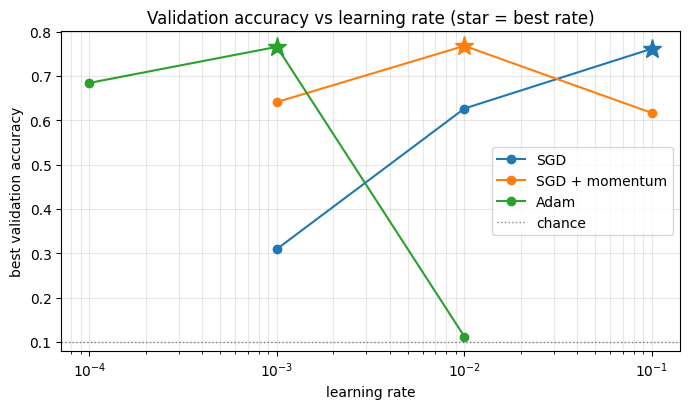

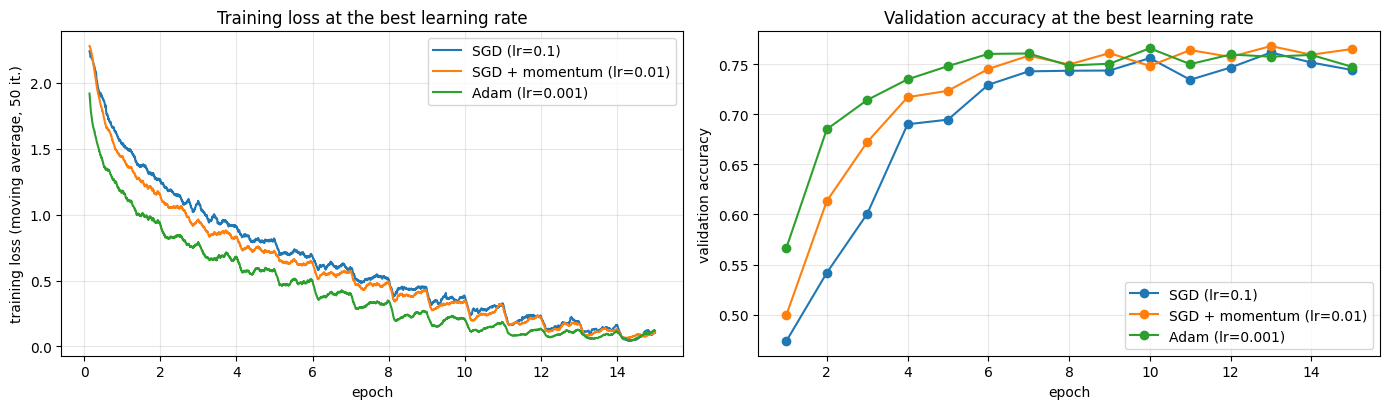

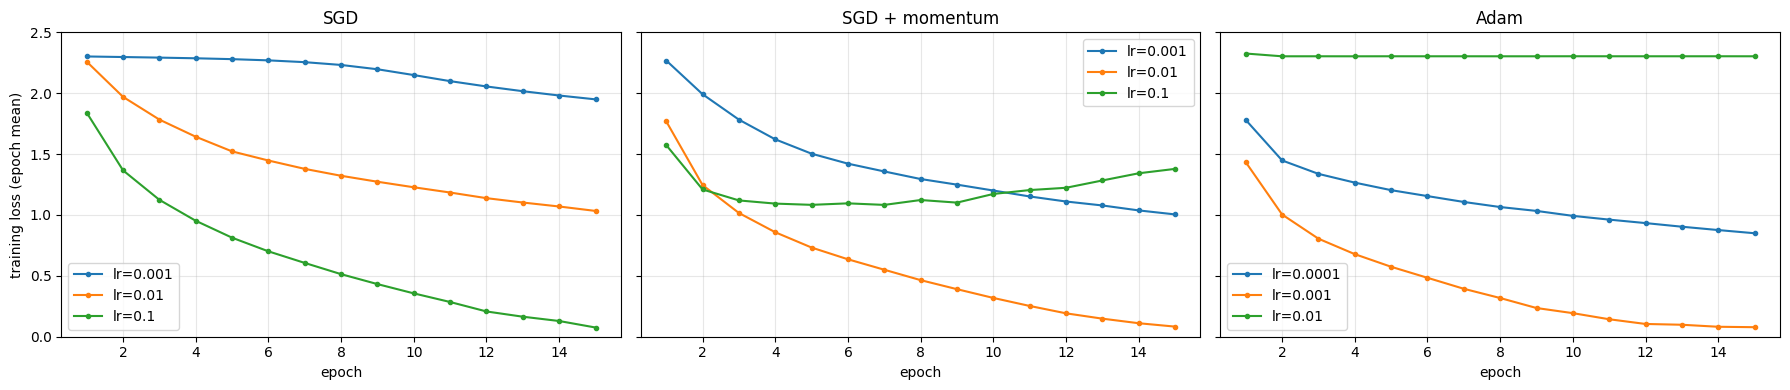

In [17]:
colors = dict(zip(LR_GRID, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

# Validation accuracy versus learning rate
fig, ax = plt.subplots(figsize=(7, 4.2))
for opt_name, (_, _, lrs) in LR_GRID.items():
    accs = [best_val_acc(cnn_results[(opt_name, lr)]) for lr in lrs]
    ax.semilogx(lrs, accs, "o-", color=colors[opt_name], label=opt_name)
    ax.plot(best_lr[opt_name], best_val_acc(cnn_results[(opt_name, best_lr[opt_name])]),
            "*", ms=14, color=colors[opt_name])
ax.axhline(0.1, color="grey", ls=":", lw=1, label="chance")
ax.set(xlabel="learning rate", ylabel="best validation accuracy",
       title="Validation accuracy vs learning rate (star = best rate)")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "t2c_val_acc_vs_lr.pdf", bbox_inches="tight")
plt.show()

# Training loss (and validation accuracy) at each optimizer's best learning rate
iters_per_epoch = math.ceil(len(Xi_tr) / CNN_BATCH)
epochs_axis = np.arange(1, CNN_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for opt_name, lr in best_lr.items():
    hist = cnn_results[(opt_name, lr)]
    smooth = np.convolve(hist["iter_loss"], np.ones(50) / 50, mode="valid")
    axes[0].plot((np.arange(len(smooth)) + 49) / iters_per_epoch, smooth,
                 color=colors[opt_name], label=f"{opt_name} (lr={lr:g})")
    axes[1].plot(epochs_axis, hist["val_acc"], "o-", color=colors[opt_name], label=f"{opt_name} (lr={lr:g})")
axes[0].set(xlabel="epoch", ylabel="training loss (moving average, 50 it.)", title="Training loss at the best learning rate")
axes[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy at the best learning rate")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "t2c_best_lr_training.pdf", bbox_inches="tight")
plt.show()

# Training loss per epoch for every learning rate (sensitivity at a glance)
fig, axes = plt.subplots(1, len(LR_GRID), figsize=(18, 4), sharey=True)
for ax, (opt_name, (_, _, lrs)) in zip(axes, LR_GRID.items()):
    for lr in lrs:
        ax.plot(epochs_axis, cnn_results[(opt_name, lr)]["train_loss"], "o-", ms=3, label=f"lr={lr:g}")
    ax.set(xlabel="epoch", title=opt_name, ylim=(0, 2.5))
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("training loss (epoch mean)")
plt.tight_layout()
fig.savefig(FIG_DIR / "t2c_train_loss_all_lrs.pdf", bbox_inches="tight")
plt.show()

#### Interpretation

**Best validation accuracy (over 15 epochs) for every run:**

| optimizer | lr = $10^{-4}$ | lr = $10^{-3}$ | lr = $10^{-2}$ | lr = $10^{-1}$ | best lr |
|---|---|---|---|---|---|
| SGD | – | 30.9% | 62.7% | **76.2%** | $10^{-1}$ |
| SGD + momentum | – | 64.1% | **76.8%** | 61.7% | $10^{-2}$ |
| Adam | 68.4% | **76.6%** | 11.2% | – | $10^{-3}$ |

**Best accuracy is similar for all three.** So the choice of optimizer matters much less than choosing a good learning rate for it. This small CNN (620k parameters) is also far better than the MLP from Task 1 which shows the value of convolutions.

**Speed differs.** The training-loss plot at the best rate shows that Adam lowers the loss fastest in the early epochs.

**Sensitivity to the learning rate**:
- **SGD** improves steadily as the learning rate grows: $ the steps are so small that the loss only falls from 2.30 to 1.95 in 15 epochs; the network has barely started learning. The best rate is at the top edge of the grid, so an even larger rate might be slightly better.

- **SGD + momentum** has a clear peak at $10^{-2}$. Momentum multiplies the effective step by $1/(1 - \mu) = 10$, so its curve is SGD's curve shifted by one decade. Compare momentum at $10^{-3}$ with SGD at $10^{-2}$ (64.1% vs 62.7%), and momentum at $10^{-2}$ with SGD at $10^{-1}$ (76.8% vs 76.2%). At $10^{-1}$ (effective step 1.0) training is unstable: the training loss falls to about 1.08 by epoch 5 and then *rises* to 1.38, and validation accuracy drops from 61.7% to 52.7%. The steps are too large for the network to settle into a minimum.

- **Adam** is the most sensitive on the high side. At $10^{-4}$ it still reaches 68.4%, because Adam's step size does not depend on how small the gradients are. But at $10^{-2}$ it **fails completely**: from epoch 2 the training loss is stuck at 2.303 = $\ln 10$, which means the network predicts the same probability (1/10) for every class on every image. Adam moves every weight by about $\eta$ per step, no matter how small its gradient is. With $\eta = 10^{-2}$ the first few updates are so large that the network collapses into a state that outputs a constant, for example because most ReLU units become *dead* (always output 0, so their gradient is 0).

**Overfitting at the best rates.** For all three optimizers the training loss goes almost to zero (≈ 0.08 after 15 epochs), but the validation loss reaches its minimum around epoch 6–7 and then rises again. For Adam it goes from 0.72 at epoch 6 to 1.22 at epoch 15. Validation accuracy stays roughly flat at about 73–77% from epoch 7 on. 

**Takeaway.** Each optimizer has its own good learning-rate range, and the ranges are shifted by about 10× from each other. Adam gives fast early progress and tolerates small rates, but it has a sharp upper limit. So the learning rate is the most important hyperparameter to tune, whichever optimizer is used.